In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# pip install yfinance
# ဒေတာဆွဲယူခြင်း
def download_stock_data(tickers, start_date, end_date):
    """
    Yahoo Finance မှ စတော့ဒေတာများ ဆွဲယူခြင်း
    """
    data = yf.download(tickers, start=start_date, end=end_date)
    return data['Adj Close']

# Technical indicators တွက်ချက်ခြင်း
def calculate_technical_indicators(df):
    """
    နည်းပညာဆိုင်ရာ indicators များ တွက်ချက်ခြင်း
    """
    df = df.copy()
    
    # Returns
    df['Return'] = df.pct_change()
    
    # Moving Averages
    df['MA_5'] = df.rolling(window=5).mean()
    df['MA_20'] = df.rolling(window=20).mean()
    df['MA_50'] = df.rolling(window=50).mean()
    
    # Volatility
    df['Volatility_5'] = df.rolling(window=5).std()
    df['Volatility_20'] = df.rolling(window=20).std()
    
    # RSI (Relative Strength Index)
    delta = df.diff()
    gain = (delta.where(delta > 0, 0)).rolling(window=14).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(window=14).mean()
    rs = gain / loss
    df['RSI'] = 100 - (100 / (1 + rs))
    
    # MACD
    exp12 = df.ewm(span=12, adjust=False).mean()
    exp26 = df.ewm(span=26, adjust=False).mean()
    df['MACD'] = exp12 - exp26
    df['MACD_Signal'] = df['MACD'].ewm(span=9, adjust=False).mean()
    
    # Bollinger Bands
    df['BB_Middle'] = df.rolling(window=20).mean()
    bb_std = df.rolling(window=20).std()
    df['BB_Upper'] = df['BB_Middle'] + (bb_std * 2)
    df['BB_Lower'] = df['BB_Middle'] - (bb_std * 2)
    
    return df.dropna()

# Target variable ဖန်တီးခြင်း
def create_target_variable(df, future_days=5):
    """
    အနာဂတ်တွင် ဈေးတက်မည်/ကျမည် ကို target variable အဖြစ် သတ်မှတ်ခြင်း
    """
    df['Future_Price'] = df.shift(-future_days)
    df['Target'] = (df['Future_Price'] > df).astype(int)
    return df.dropna()

# Main execution
def stock_prediction_with_pca(ticker='AAPL', start_date='2020-01-01', end_date='2023-12-31'):
    """
    PCA ကို အသုံးပြု၍ စတော့ဈေးကွက် ခန့်မှန်းခြင်း
    """
    # ဒေတာဆွဲယူခြင်း
    print("Downloading stock data...")
    stock_data = download_stock_data(ticker, start_date, end_date)
    
    # Technical indicators တွက်ချက်ခြင်း
    print("Calculating technical indicators...")
    df_with_indicators = calculate_technical_indicators(stock_data)
    
    # Target variable ဖန်တီးခြင်း
    print("Creating target variable...")
    df_final = create_target_variable(df_with_indicators)
    
    # Features and target ခွဲခြင်း
    features = df_final.drop(['Future_Price', 'Target'], axis=1, errors='ignore')
    target = df_final['Target']
    
    # Missing values ကိုင်တွယ်ခြင်း
    features = features.fillna(features.mean())
    
    # Data scaling
    print("Scaling data...")
    scaler = StandardScaler()
    features_scaled = scaler.fit_transform(features)
    
    # PCA application
    print("Applying PCA...")
    pca = PCA(n_components=0.95)  # 95% variance retain
    features_pca = pca.fit_transform(features_scaled)
    
    print(f"Original features: {features.shape[1]}")
    print(f"After PCA features: {features_pca.shape[1]}")
    print(f"Explained variance ratio: {sum(pca.explained_variance_ratio_):.3f}")
    
    # Train-test split
    X_train, X_test, y_train, y_test = train_test_split(
        features_pca, target, test_size=0.2, random_state=42, shuffle=False
    )
    
    # Model training
    print("Training model...")
    model = RandomForestClassifier(n_estimators=100, random_state=42)
    model.fit(X_train, y_train)
    
    # Prediction
    y_pred = model.predict(X_test)
    
    # Evaluation
    accuracy = accuracy_score(y_test, y_pred)
    print(f"\nModel Accuracy: {accuracy:.3f}")
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))
    
    return {
        'model': model,
        'pca': pca,
        'scaler': scaler,
        'features': features,
        'accuracy': accuracy,
        'explained_variance': sum(pca.explained_variance_ratio_)
    }

# ရလဒ်များကို visualization လုပ်ခြင်း
def visualize_results(results, ticker):
    """
    PCA results များကို visualization လုပ်ခြင်း
    """
    pca = results['pca']
    
    # Explained variance plot
    plt.figure(figsize=(15, 5))
    
    # Plot 1: Cumulative explained variance
    plt.subplot(131)
    plt.plot(np.cumsum(pca.explained_variance_ratio_))
    plt.xlabel('Number of Components')
    plt.ylabel('Cumulative Explained Variance')
    plt.title('Cumulative Explained Variance')
    plt.grid(True)
    
    # Plot 2: Feature importance from PCA components
    plt.subplot(132)
    component_importance = pca.explained_variance_ratio_
    plt.bar(range(len(component_importance)), component_importance)
    plt.xlabel('Principal Components')
    plt.ylabel('Explained Variance Ratio')
    plt.title('Component Importance')
    
    # Plot 3: First two principal components
    plt.subplot(133)
    if hasattr(results, 'features_pca'):
        plt.scatter(results['features_pca'][:, 0], results['features_pca'][:, 1], alpha=0.5)
        plt.xlabel('First Principal Component')
        plt.ylabel('Second Principal Component')
        plt.title('PCA Components Scatter Plot')
    
    plt.tight_layout()
    plt.suptitle(f'PCA Analysis for {ticker} Stock Prediction', y=1.02)
    plt.show()

# Example usage
if __name__ == "__main__":
    # Apple stock အတွက် prediction
    results = stock_prediction_with_pca(ticker='AAPL', 
                                      start_date='2020-01-01', 
                                      end_date='2023-12-31')
    
    # Results visualization
    visualize_results(results, 'AAPL')
    
    # Print component details
    print(f"\nTotal explained variance: {results['explained_variance']:.3f}")
    print(f"Model accuracy: {results['accuracy']:.3f}")

C:\Users\E15\AppData\Local\Temp\ipykernel_19292\1883001153.py:18: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers, start=start_date, end=end_date)
[*********************100%***********************]  1 of 1 completed


KeyError: 'Adj Close'

## Example 2 Fixed Code with Error Handling

In [2]:
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# Alternative data source သုံးခြင်း
def get_stock_data():
    """
    CSV file ကနေ ဒေတာဖတ်ခြင်း (သို့) synthetic data ဖန်တီးခြင်း
    """
    try:
        # Try to use yfinance if available
        import yfinance as yf
        print("Using yfinance for data...")
        data = yf.download('AAPL', start='2020-01-01', end='2023-12-31')
        if 'Adj Close' in data.columns:
            return data['Adj Close']
        elif 'Close' in data.columns:
            return data['Close']
        else:
            return data.iloc[:, 0]  # First column
    except:
        # Fallback to synthetic data
        print("Using synthetic data...")
        return create_synthetic_data()

def create_synthetic_data(days=1000, initial_price=100):
    """
    Synthetic stock data ဖန်တီးခြင်း
    """
    np.random.seed(42)
    returns = np.random.normal(0.001, 0.02, days)
    prices = initial_price * np.exp(np.cumsum(returns))
    dates = pd.date_range(start='2020-01-01', periods=days, freq='D')
    return pd.Series(prices, index=dates, name='Price')

# Technical indicators တွက်ချက်ခြင်း
def calculate_technical_indicators(price_series):
    """
    နည်းပညာဆိုင်ရာ indicators များ တွက်ချက်ခြင်း
    """
    df = pd.DataFrame({'Price': price_series})
    
    # Returns
    df['Return'] = df['Price'].pct_change()
    
    # Moving Averages
    df['MA_5'] = df['Price'].rolling(window=5).mean()
    df['MA_20'] = df['Price'].rolling(window=20).mean()
    df['MA_50'] = df['Price'].rolling(window=50).mean()
    
    # Volatility
    df['Volatility_5'] = df['Price'].rolling(window=5).std()
    df['Volatility_20'] = df['Price'].rolling(window=20).std()
    
    # RSI (Relative Strength Index)
    delta = df['Price'].diff()
    gain = (delta.where(delta > 0, 0)).rolling(window=14).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(window=14).mean()
    rs = gain / loss
    df['RSI'] = 100 - (100 / (1 + rs))
    
    # MACD
    exp12 = df['Price'].ewm(span=12, adjust=False).mean()
    exp26 = df['Price'].ewm(span=26, adjust=False).mean()
    df['MACD'] = exp12 - exp26
    df['MACD_Signal'] = df['MACD'].ewm(span=9, adjust=False).mean()
    
    # Bollinger Bands
    df['BB_Middle'] = df['Price'].rolling(window=20).mean()
    bb_std = df['Price'].rolling(window=20).std()
    df['BB_Upper'] = df['BB_Middle'] + (bb_std * 2)
    df['BB_Lower'] = df['BB_Middle'] - (bb_std * 2)
    
    return df.dropna()

# Target variable ဖန်တီးခြင်း
def create_target_variable(df, future_days=5):
    """
    အနာဂတ်တွင် ဈေးတက်မည်/ကျမည် ကို target variable အဖြစ် သတ်မှတ်ခြင်း
    """
    df = df.copy()
    df['Future_Price'] = df['Price'].shift(-future_days)
    df['Target'] = (df['Future_Price'] > df['Price']).astype(int)
    return df.dropna()

# Main execution
def stock_prediction_with_pca():
    """
    PCA ကို အသုံးပြု၍ စတော့ဈေးကွက် ခန့်မှန်းခြင်း
    """
    # ဒေတာရယူခြင်း
    print("Loading stock data...")
    price_data = get_stock_data()
    
    # Technical indicators တွက်ချက်ခြင်း
    print("Calculating technical indicators...")
    df_with_indicators = calculate_technical_indicators(price_data)
    
    # Target variable ဖန်တီးခြင်း
    print("Creating target variable...")
    df_final = create_target_variable(df_with_indicators)
    
    # Features and target ခွဲခြင်း
    features = df_final.drop(['Future_Price', 'Target'], axis=1, errors='ignore')
    target = df_final['Target']
    
    # Missing values ကိုင်တွယ်ခြင်း
    features = features.fillna(features.mean())
    
    # Data scaling
    print("Scaling data...")
    scaler = StandardScaler()
    features_scaled = scaler.fit_transform(features)
    
    # PCA application
    print("Applying PCA...")
    pca = PCA(n_components=0.95)  # 95% variance retain
    features_pca = pca.fit_transform(features_scaled)
    
    print(f"Original features: {features.shape[1]}")
    print(f"After PCA features: {features_pca.shape[1]}")
    print(f"Explained variance ratio: {sum(pca.explained_variance_ratio_):.3f}")
    
    # Train-test split
    X_train, X_test, y_train, y_test = train_test_split(
        features_pca, target, test_size=0.2, random_state=42, shuffle=False
    )
    
    # Model training
    print("Training model...")
    model = RandomForestClassifier(n_estimators=100, random_state=42)
    model.fit(X_train, y_train)
    
    # Prediction
    y_pred = model.predict(X_test)
    
    # Evaluation
    accuracy = accuracy_score(y_test, y_pred)
    print(f"\nModel Accuracy: {accuracy:.3f}")
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))
    
    return {
        'model': model,
        'pca': pca,
        'scaler': scaler,
        'features': features,
        'features_pca': features_pca,
        'target': target,
        'accuracy': accuracy,
        'explained_variance': sum(pca.explained_variance_ratio_)
    }

# ရလဒ်များကို visualization လုပ်ခြင်း
def visualize_results(results):
    """
    PCA results များကို visualization လုပ်ခြင်း
    """
    pca = results['pca']
    features_pca = results['features_pca']
    target = results['target']
    
    plt.figure(figsize=(15, 5))
    
    # Plot 1: Cumulative explained variance
    plt.subplot(131)
    plt.plot(np.cumsum(pca.explained_variance_ratio_))
    plt.xlabel('Number of Components')
    plt.ylabel('Cumulative Explained Variance')
    plt.title('Cumulative Explained Variance')
    plt.grid(True)
    
    # Plot 2: Feature importance from PCA components
    plt.subplot(132)
    component_importance = pca.explained_variance_ratio_
    plt.bar(range(len(component_importance)), component_importance)
    plt.xlabel('Principal Components')
    plt.ylabel('Explained Variance Ratio')
    plt.title('Component Importance')
    
    # Plot 3: First two principal components with target colors
    plt.subplot(133)
    scatter = plt.scatter(features_pca[:, 0], features_pca[:, 1], 
                         c=target, cmap='viridis', alpha=0.6)
    plt.xlabel('First Principal Component')
    plt.ylabel('Second Principal Component')
    plt.title('PCA Components with Target Colors')
    plt.colorbar(scatter, label='Target (0=Down, 1=Up)')
    
    plt.tight_layout()
    plt.show()

# Feature importance analysis
def analyze_feature_importance(results):
    """
    PCA components နဲ့ original features ကြားက relationship ကို analysis လုပ်ခြင်း
    """
    pca = results['pca']
    feature_names = results['features'].columns.tolist()
    
    print("\n" + "="*50)
    print("PCA COMPONENT ANALYSIS")
    print("="*50)
    
    # Component loadings
    loadings = pca.components_
    
    for i, component in enumerate(loadings):
        print(f"\nPrincipal Component {i+1}:")
        # Feature names နဲ့ loadings ကို pair လုပ်ခြင်း
        feature_loading = list(zip(feature_names, component))
        # Loading အကြီးဆုံး features 5 ခုကို ပြခြင်း
        sorted_features = sorted(feature_loading, key=lambda x: abs(x[1]), reverse=True)[:5]
        
        for feature, loading in sorted_features:
            print(f"  {feature}: {loading:.3f}")

# Example usage
if __name__ == "__main__":
    # Run stock prediction
    results = stock_prediction_with_pca()
    
    # Results visualization
    visualize_results(results)
    
    # Feature importance analysis
    analyze_feature_importance(results)
    
    # Print summary
    print(f"\n{'='*50}")
    print("SUMMARY RESULTS")
    print(f"{'='*50}")
    print(f"Total explained variance: {results['explained_variance']:.3f}")
    print(f"Model accuracy: {results['accuracy']:.3f}")
    print(f"Original features: {results['features'].shape[1]}")
    print(f"PCA features: {results['features_pca'].shape[1]}")
    print(f"Dataset size: {len(results['features'])} samples")

C:\Users\E15\AppData\Local\Temp\ipykernel_19292\3488606969.py:20: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download('AAPL', start='2020-01-01', end='2023-12-31')
[*********************100%***********************]  1 of 1 completed

Loading stock data...
Using yfinance for data...
Calculating technical indicators...


ValueError: If using all scalar values, you must pass an index

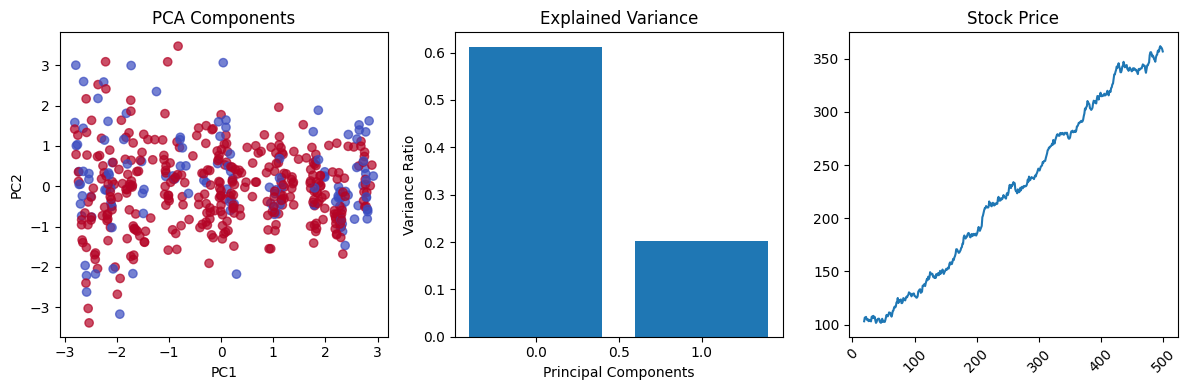

Accuracy: 0.619
Explained variance: 0.814


In [3]:
# Simplified Version
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

# Simple synthetic data creation
def create_simple_stock_data():
    np.random.seed(42)
    days = 500
    prices = 100 + np.cumsum(np.random.normal(0.5, 2, days))
    return pd.Series(prices, name='Price')

# Simple technical indicators
def create_features(price_series):
    df = pd.DataFrame({'Price': price_series})
    df['Return'] = df['Price'].pct_change()
    df['MA_5'] = df['Price'].rolling(5).mean()
    df['MA_20'] = df['Price'].rolling(20).mean()
    df['Volatility'] = df['Price'].rolling(20).std()
    df['Target'] = (df['Price'].shift(-5) > df['Price']).astype(int)
    return df.dropna()

# Main function
def simple_pca_stock_prediction():
    # Create data
    prices = create_simple_stock_data()
    df = create_features(prices)
    
    # Prepare features and target
    X = df.drop('Target', axis=1)
    y = df['Target']
    
    # Scale and apply PCA
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    pca = PCA(n_components=2)
    X_pca = pca.fit_transform(X_scaled)
    
    # Train model
    X_train, X_test, y_train, y_test = train_test_split(
        X_pca, y, test_size=0.2, random_state=42
    )
    
    model = RandomForestClassifier(n_estimators=50, random_state=42)
    model.fit(X_train, y_train)
    
    # Evaluate
    accuracy = accuracy_score(y_test, model.predict(X_test))
    
    # Plot results
    plt.figure(figsize=(12, 4))
    
    plt.subplot(131)
    plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='coolwarm', alpha=0.7)
    plt.xlabel('PC1')
    plt.ylabel('PC2')
    plt.title('PCA Components')
    
    plt.subplot(132)
    plt.bar(range(len(pca.explained_variance_ratio_)), pca.explained_variance_ratio_)
    plt.xlabel('Principal Components')
    plt.ylabel('Variance Ratio')
    plt.title('Explained Variance')
    
    plt.subplot(133)
    plt.plot(df.index, df['Price'])
    plt.title('Stock Price')
    plt.xticks(rotation=45)
    
    plt.tight_layout()
    plt.show()
    
    print(f"Accuracy: {accuracy:.3f}")
    print(f"Explained variance: {sum(pca.explained_variance_ratio_):.3f}")

# Run the simple version
simple_pca_stock_prediction()